<a href="https://colab.research.google.com/github/ekupinsk/hebrew-image-search/blob/main/hebrew_image_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# חיפוש תמונות בעברית: השוואת מודלים
הכנת המאגר, תרגום, יצירת וקטורים, מדידה, והעלאה ל-Hugging Face. הרצה אחת מלמעלה למטה.

לפני ההרצה: ב-Colab בחר `Runtime → Change runtime type → T4 GPU`. ב-Kaggle: `Settings → Accelerator → GPU`.

זמן ריצה משוער: 15–25 דקות (רוב הזמן הוא התרגום).

</div>

In [1]:
!pip install -q sentence-transformers datasets transformers sentencepiece sacremoses huggingface_hub pandas

In [2]:
import os, re, json, random
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from transformers import MarianMTModel, MarianTokenizer, AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("WARNING: no GPU found - this will be very slow. Switch the runtime to GPU.")

OUT = "hebrew_clip_search"
os.makedirs(f"{OUT}/images", exist_ok=True)
os.makedirs(f"{OUT}/embeddings", exist_ok=True)
random.seed(42)

Device: cuda


<div dir="rtl">

## 1. טעינת Flickr30k (סט הבדיקה של 1,000 תמונות)
הדפסת המבנה עוזרת לוודא שהעמודות הן מה שאנחנו מצפים להן.

</div>

TEST/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  142MB            

TEST/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image', 'caption', 'sentids', 'imgid', 'split', 'filename', 'tokens', 'sentid'],
    num_rows: 1000
})


Loading:   0%|          | 0/1000 [00:00<?, ?it/s]

1000 images, 5000 captions
Example: The man with pierced ears is wearing glasses and an orange hat.


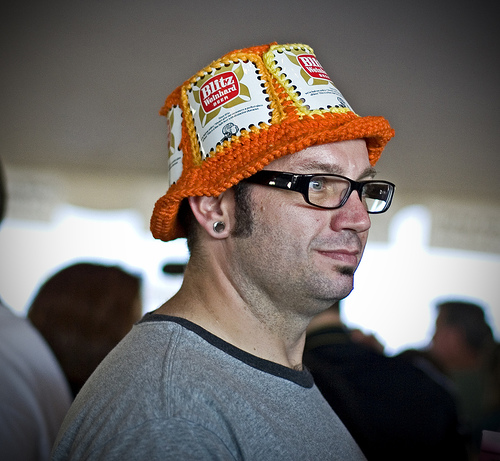

In [3]:
# The repo uses an old loading script that new `datasets` versions reject,
# so we read Hugging Face's auto-converted Parquet copy directly.
import io
from PIL import Image

PARQUET = "hf://datasets/nlphuji/flickr_1k_test_image_text_retrieval@refs%2Fconvert%2Fparquet/**/*.parquet"
ds = load_dataset("parquet", data_files=PARQUET, split="train")
print(ds)

def to_pil(x):
    # usually already a PIL image; fall back to raw bytes if not
    if isinstance(x, dict):
        x = Image.open(io.BytesIO(x["bytes"]))
    return x

def as_list(c):
    # captions may arrive as a list or as a JSON-encoded string
    if isinstance(c, str):
        try:
            c = json.loads(c)
        except json.JSONDecodeError:
            c = [c]
    return list(c)

images, captions_en, caption_img_idx = [], [], []
for i, ex in enumerate(tqdm(ds, desc="Loading")):
    img = to_pil(ex["image"]).convert("RGB")
    images.append(img)
    img.save(f"{OUT}/images/{i:04d}.jpg", quality=90)
    for cap in as_list(ex["caption"]):
        captions_en.append(cap)
        caption_img_idx.append(i)

caption_img_idx = np.array(caption_img_idx)
print(f"{len(images)} images, {len(captions_en)} captions")
print("Example:", captions_en[0])
images[0]

<div dir="rtl">

## 2. תרגום הכיתובים לעברית, ותרגום חזרה לאנגלית
- `en → he`: יוצר את שאילתות הבדיקה בעברית.
- `he → en`: מה שהגישה של "תרגום ואז CLIP" תקבל בזמן אמת.

</div>

In [4]:
def translate(texts, model_name, bs=64):
    tok = MarianTokenizer.from_pretrained(model_name)
    model = MarianMTModel.from_pretrained(model_name).to(device).eval()
    if device == "cuda":
        model = model.half()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc=model_name.split("/")[-1]):
        batch = tok(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True).to(device)
        with torch.no_grad():
            gen = model.generate(**batch, max_length=256, num_beams=4)
        out += tok.batch_decode(gen, skip_special_tokens=True)
    del model
    torch.cuda.empty_cache()
    return out

captions_he = translate(captions_en, "Helsinki-NLP/opus-mt-en-he")
captions_he2en = translate(captions_he, "Helsinki-NLP/opus-mt-tc-big-he-en")

for i in random.sample(range(len(captions_en)), 5):
    print("EN   :", captions_en[i])
    print("HE   :", captions_he[i])
    print("HE>EN:", captions_he2en[i])
    print("-" * 60)

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/799k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/890k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.15M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

opus-mt-tc-big-he-en:   0%|          | 0/79 [00:00<?, ?it/s]

EN   : A young boy in a team sweatshirt is in a sports stadium near blue seats swinging a red bat.
HE   : נער צעיר בסווטשירט קבוצתי נמצא באצטדיון ספורט ליד מושבים כחולים מתנדנדים במחבט אדום.
HE>EN: A young boy in a group sweatshirt is found in a sports stadium near blue seats swinging in a red bat.
------------------------------------------------------------
EN   : A girl floating wearing a life vest.
HE   : בחורה צפה לובשת אפוד הצלה.
HE>EN: A girl watched wearing a life vest.
------------------------------------------------------------
EN   : Boy in red shirt and black shorts sweeps driveway.
HE   : ילד בחולצה אדומה ומכנסיים קצרים שחורים מטאטא את שביל הגישה.
HE>EN: A boy in a red shirt and black shorts sweeps the driveway.
------------------------------------------------------------
EN   : While visiting the Mayan ruins, a guide points in the direction of more attractions.
HE   : בשעה שביקרו בחורבות בני המאיה, מדריך מצביע על כיוון של אטרקציות נוספות.
HE>EN: While visiting the Mayan ru

In [5]:
# Save all captions, plus a 100-row sample for manual review
captions = [
    {"img": int(caption_img_idx[i]), "en": captions_en[i], "he": captions_he[i], "he2en": captions_he2en[i]}
    for i in range(len(captions_en))
]
with open(f"{OUT}/captions.json", "w", encoding="utf-8") as f:
    json.dump(captions, f, ensure_ascii=False, indent=1)

review_idx = sorted(random.sample(range(len(captions)), 100))
pd.DataFrame(
    [{"row": i, "img": captions[i]["img"], "en": captions[i]["en"], "he_machine": captions[i]["he"], "he_fixed": ""} for i in review_idx]
).to_csv(f"{OUT}/manual_review.csv", index=False, encoding="utf-8-sig")
print("Saved captions.json and manual_review.csv")

Saved captions.json and manual_review.csv


<div dir="rtl">

## 3. וקטורים לתמונות: שתי ריצות בלבד
- **ViT-B/32**: משותף ל-CLIP באנגלית ולמודל הרב-לשוני.
- **ViT-L/14**: משותף ל-CLIP הגדול באנגלית ול-HebCLIP של NVIDIA (שמיושר בדיוק למקודד הזה).

</div>

In [6]:
IMAGE_ENCODERS = {"B32": "clip-ViT-B-32", "L14": "clip-ViT-L-14"}
img_emb = {}

for key, name in IMAGE_ENCODERS.items():
    model = SentenceTransformer(name, device=device)
    emb = model.encode(images, batch_size=64, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=True)
    img_emb[key] = emb.astype(np.float32)
    np.save(f"{OUT}/embeddings/images_{key}.npy", img_emb[key])
    print(key, emb.shape)
    del model
    torch.cuda.empty_cache()

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

0_CLIPModel/model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

L14 (1000, 768)


<div dir="rtl">

## 4. מדידה: Recall@K
לכל שאילתה בודקים אם התמונה הנכונה הופיעה ב-K התוצאות הראשונות.

שתי השורות עם הכיתובים המקוריים באנגלית הן **תקרת ייחוס**: כמה טוב המודל עובד בלי שום עברית. הפער מהן מראה כמה "עולה" לנו העברית.

</div>

In [7]:
def recall_at_k(q, imgs, gt, ks=(1, 5, 10)):
    sims = torch.from_numpy(q) @ torch.from_numpy(imgs).T
    top = sims.topk(max(ks), dim=1).indices.numpy()
    hits = top == gt[:, None]
    return {f"R@{k}": round(hits[:, :k].any(axis=1).mean() * 100, 2) for k in ks}

def encode_hebclip(texts, bs=128):
    # NVIDIA HebCLIP: mean of the last hidden state over real tokens, as in its model card
    tok = AutoTokenizer.from_pretrained("nvidia/hebclip-model")
    model = AutoModel.from_pretrained("nvidia/hebclip-model").to(device).eval()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc="HebCLIP"):
        batch = tok(texts[i:i+bs], padding=True, truncation=True, max_length=77, return_tensors="pt").to(device)
        with torch.no_grad():
            hidden = model(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        emb = (hidden * mask).sum(1) / mask.sum(1)
        out.append(torch.nn.functional.normalize(emb, dim=-1).cpu().numpy())
    del model
    torch.cuda.empty_cache()
    return np.concatenate(out).astype(np.float32)

def encode_text(model_name, texts):
    if model_name == "nvidia/hebclip-model":
        return encode_hebclip(texts)
    model = SentenceTransformer(model_name, device=device)
    emb = model.encode(texts, batch_size=256, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=True)
    del model
    torch.cuda.empty_cache()
    return emb.astype(np.float32)

# (row name, text model, input texts, image encoder)
EXPERIMENTS = [
    ("Reference: English captions, CLIP B/32",       "clip-ViT-B-32",                                     captions_en,    "B32"),
    ("Hebrew -> translate -> CLIP B/32",            "clip-ViT-B-32",                                     captions_he2en, "B32"),
    ("Hebrew direct, multilingual CLIP B/32",       "sentence-transformers/clip-ViT-B-32-multilingual-v1", captions_he,   "B32"),
    ("Reference: English captions, CLIP L/14",       "clip-ViT-L-14",                                     captions_en,    "L14"),
    ("Hebrew -> translate -> CLIP L/14",            "clip-ViT-L-14",                                     captions_he2en, "L14"),
    ("Hebrew direct, NVIDIA HebCLIP L/14",          "nvidia/hebclip-model",                              captions_he,    "L14"),
]

results = []
for row_name, model_name, texts, enc in EXPERIMENTS:
    print("\n==>", row_name)
    q = encode_text(model_name, texts)
    tag = re.sub(r"[^A-Za-z0-9]+", "_", row_name).strip("_")  # safe file name (no "/")
    np.save(f"{OUT}/embeddings/text_{enc}_{tag}.npy", q)
    r = recall_at_k(q, img_emb[enc], caption_img_idx)
    results.append({"method": row_name, "image_encoder": enc, **r})
    print(r)

df = pd.DataFrame(results)
df.to_csv(f"{OUT}/results.csv", index=False)
df


==> Reference: English captions, CLIP B/32


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

{'R@1': np.float64(58.78), 'R@5': np.float64(83.42), 'R@10': np.float64(90.06)}

==> Hebrew -> translate -> CLIP B/32


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

HebCLIP:   0%|          | 0/40 [00:00<?, ?it/s]

{'R@1': np.float64(54.22), 'R@5': np.float64(79.72), 'R@10': np.float64(87.0)}


,method,image_encoder,R@1,R@5,R@10
0,"Reference: English captions, CLIP B/32",B32,58.78,83.42,90.06
1,Hebrew -> translate -> CLIP B/32,B32,54.62,79.42,87.02
2,"Hebrew direct, multilingual CLIP B/32",B32,30.40,55.68,66.52
3,"Reference: English captions, CLIP L/14",L14,64.58,87.08,92.08
4,Hebrew -> translate -> CLIP L/14,L14,60.74,83.40,89.58
5,"Hebrew direct, NVIDIA HebCLIP L/14",L14,54.22,79.72,87.00


<div dir="rtl">

## 5. העלאה ל-Hugging Face
התמונות, הכיתובים, הווקטורים והתוצאות נשמרים כ-Dataset ב-Hugging Face, ומשם אפליקציית הדמו טוענת אותם.

</div>

In [ ]:
from huggingface_hub import login, HfApi
login()  # paste your Write token when prompted

HF_USERNAME = HfApi().whoami()["name"]
REPO_ID = f"{HF_USERNAME}/hebrew-clip-search-data"

api = HfApi()
api.create_repo(REPO_ID, repo_type="dataset", exist_ok=True, private=False)
api.upload_folder(folder_path=OUT, repo_id=REPO_ID, repo_type="dataset",
                  commit_message="Flickr30k 1k test: Hebrew captions, embeddings, results")
print(f"Done: https://huggingface.co/datasets/{REPO_ID}")